# Model comparison, plots and final results (owner: Sriniket Deeduvanu)

In [1]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


,model,val_micro_f1,val_accuracy_percent
0,gradient_boosting,0.734330,73.43
1,random_forest,0.731509,73.15
2,neural_network,0.697224,69.72
3,knn,0.680244,68.02


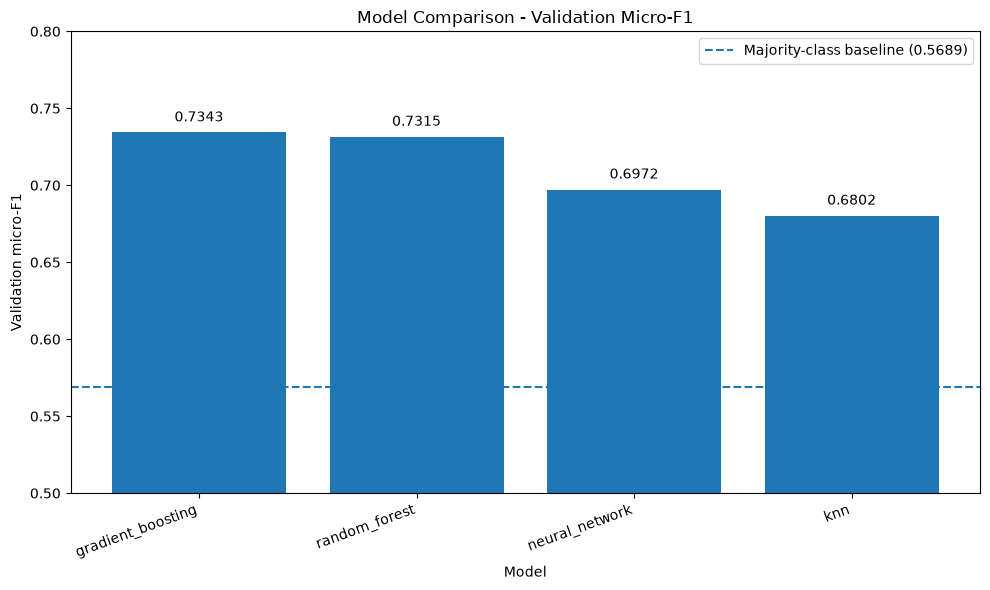

In [2]:

import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

metrics_dir = Path("results/metrics")
figures_dir = Path("results/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

model_files = [
    "knn.json",
    "random_forest.json",
    "gradient_boosting.json",
    "neural_network.json",
]

results = []

for filename in model_files:
    file = metrics_dir / filename
    if file.exists():
        with open(file, "r") as f:
            results.append(json.load(f))
    else:
        print(f"Warning: {filename} not found.")

comparison_df = pd.DataFrame(results)

if comparison_df.empty:
    print("No saved model metrics found yet.")
else:
    comparison_df = comparison_df.sort_values(
        "val_micro_f1", ascending=False
    ).reset_index(drop=True)

    comparison_df["val_accuracy_percent"] = (
        comparison_df["val_micro_f1"] * 100
    ).round(2)

    display(comparison_df)

    # Validation micro-F1 comparison
    baseline_score = 0.5689

    plt.figure(figsize=(10, 6))
    bars = plt.bar(
        comparison_df["model"].astype(str),
        comparison_df["val_micro_f1"]
    )

    plt.axhline(
        y=baseline_score,
        linestyle="--",
        linewidth=1.5,
        label=f"Majority-class baseline ({baseline_score:.4f})"
    )

    plt.ylabel("Validation micro-F1")
    plt.xlabel("Model")
    plt.title("Model Comparison - Validation Micro-F1")
    plt.ylim(0.50, 0.80)
    plt.xticks(rotation=20, ha="right")
    plt.legend()

    for bar, score in zip(bars, comparison_df["val_micro_f1"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            score + 0.005,
            f"{score:.4f}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.savefig(
        figures_dir / "model_comparison.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

In [3]:

from sklearn.metrics import classification_report, f1_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier

# Recreate the shared data split
X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)

# Configure models using the selected hyperparameters
models = {
    "Random Forest": Pipeline([
        ("preprocessor", build_tree_preprocessor(X_train)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", build_tree_preprocessor(X_train)),
        ("classifier", HistGradientBoostingClassifier(
            learning_rate=0.1,
            max_iter=250,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=42
        ))
    ])
}

# Fit the two tuned tree models and collect per-class metrics
recall_results = []
macro_f1_results = []

for name, model in models.items():
    print(f"Evaluating {name}...")
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    report = classification_report(
        y_val, predictions, output_dict=True, zero_division=0
    )

    for grade in ["1", "2", "3"]:
        recall_results.append({
            "model": name,
            "damage_grade": grade,
            "recall": report[grade]["recall"]
        })

    macro_f1_results.append({
        "model": name,
        "macro_f1": f1_score(y_val, predictions, average="macro")
    })

recall_df = pd.DataFrame(recall_results)
macro_f1_df = pd.DataFrame(macro_f1_results)

print("Per-class recall:")
display(recall_df.pivot(
    index="model", columns="damage_grade", values="recall"
).round(4))

print("Macro-F1:")
display(macro_f1_df.round(4))

Evaluating Random Forest...
Evaluating Gradient Boosting...
Per-class recall:


damage_grade,1,2,3
model,,,
Gradient Boosting,0.4874,0.8522,0.6051
Random Forest,0.4464,0.8624,0.5911


Macro-F1:


,model,macro_f1
0,Random Forest,0.6650
1,Gradient Boosting,0.6764


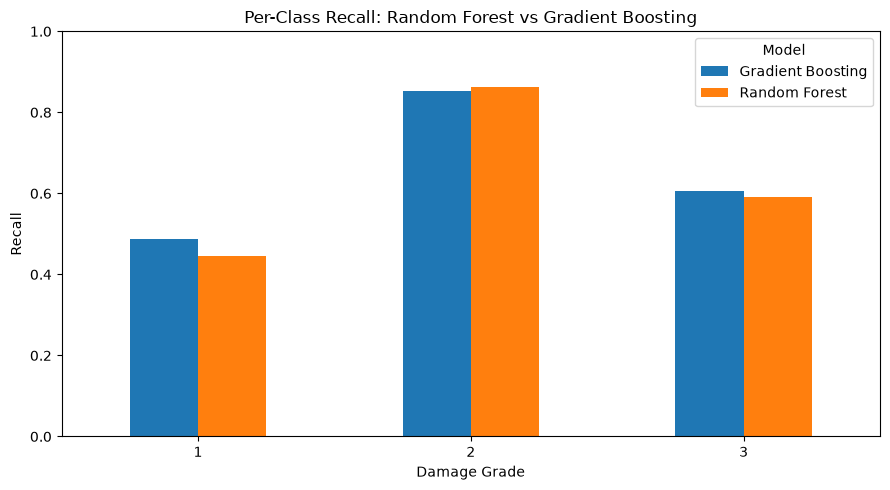

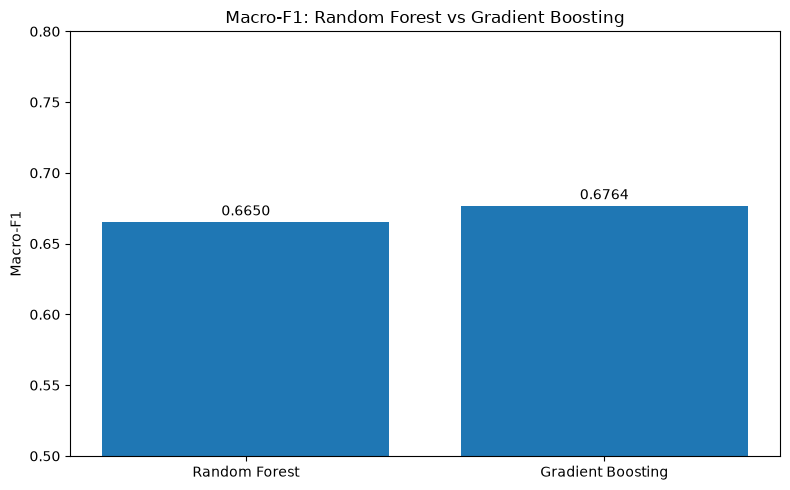

In [4]:

import matplotlib.pyplot as plt

# Per-class recall comparison
recall_pivot = recall_df.pivot(
    index="damage_grade",
    columns="model",
    values="recall"
)

ax = recall_pivot.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1)
)
ax.set_title("Per-Class Recall: Random Forest vs Gradient Boosting")
ax.set_xlabel("Damage Grade")
ax.set_ylabel("Recall")
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    figures_dir / "per_class_recall.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Macro-F1 comparison
plt.figure(figsize=(8, 5))
bars = plt.bar(
    macro_f1_df["model"],
    macro_f1_df["macro_f1"]
)
plt.ylabel("Macro-F1")
plt.title("Macro-F1: Random Forest vs Gradient Boosting")
plt.ylim(0.50, 0.80)

for bar, score in zip(bars, macro_f1_df["macro_f1"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.005,
        f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    figures_dir / "macro_f1_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

Calculating feature importance for Random Forest...
Calculating feature importance for Gradient Boosting...


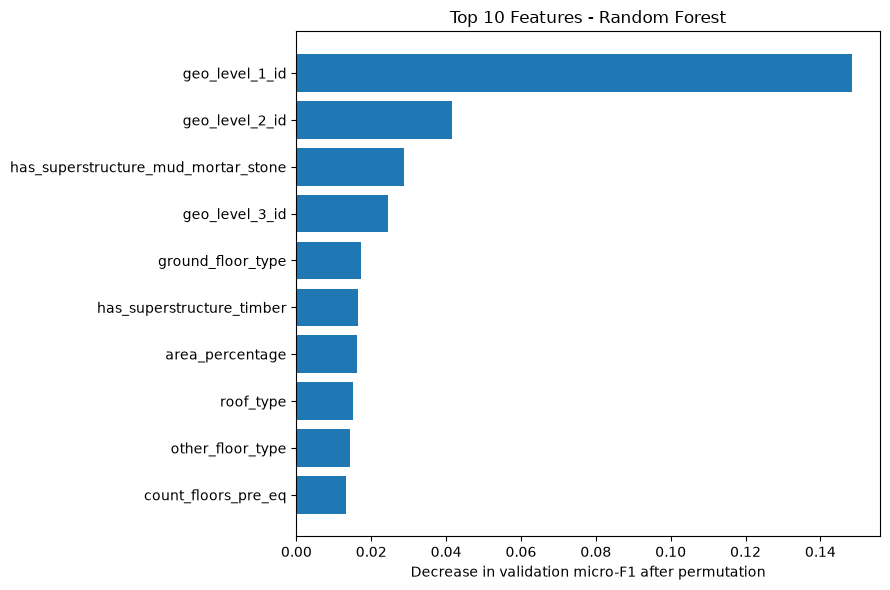

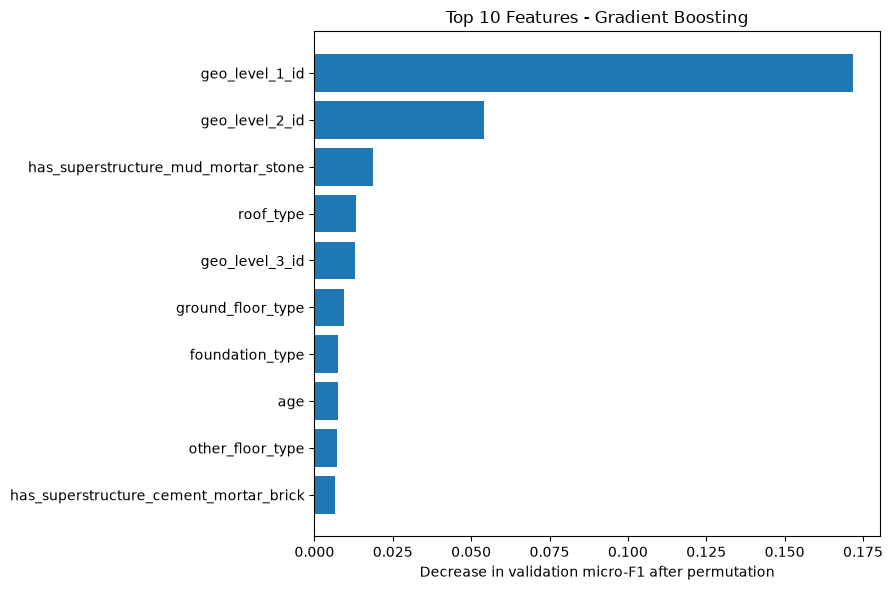

Feature importance calculated using 2000 validation rows.


In [5]:

from sklearn.inspection import permutation_importance

# Use a small validation sample to keep computation manageable
sample_size = min(2000, len(X_val))
X_sample = X_val.sample(n=sample_size, random_state=42)
y_sample = y_val.loc[X_sample.index]

importance_results = []

for name, model in models.items():
    print(f"Calculating feature importance for {name}...")

    importance = permutation_importance(
        model,
        X_sample,
        y_sample,
        scoring="f1_micro",
        n_repeats=3,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "feature": X_sample.columns,
        "importance": importance.importances_mean
    }).sort_values("importance", ascending=False)

    importance_df["model"] = name
    importance_results.append(importance_df)

importance_all = pd.concat(importance_results, ignore_index=True)

# Plot the top 10 features for each model
for name in models:
    top_features = (
        importance_all[importance_all["model"] == name]
        .nlargest(10, "importance")
        .sort_values("importance")
    )

    plt.figure(figsize=(9, 6))
    plt.barh(top_features["feature"], top_features["importance"])
    plt.xlabel("Decrease in validation micro-F1 after permutation")
    plt.title(f"Top 10 Features - {name}")
    plt.tight_layout()

    safe_name = name.lower().replace(" ", "_")
    plt.savefig(
        figures_dir / f"{safe_name}_feature_importance.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

print("Feature importance calculated using", sample_size, "validation rows.")

In [ ]:
## Overall Model Comparison and Conclusion

### Model Performance

Four models were evaluated using validation micro-F1:

| Model             | Validation micro-F1 |
| ----------------- | ------------------: |
| Gradient Boosting |              0.7343 |
| Random Forest     |              0.7315 |
| Neural Network    |              0.6972 |
| KNN               |              0.6802 |

The majority-class baseline was 0.5689. All four models outperformed this baseline. Gradient Boosting achieved the highest validation micro-F1 at 73.43%, narrowly outperforming Random Forest at 73.15%.

### Class-Wise Performance

Gradient Boosting achieved a macro-F1 of 0.6764, compared with 0.6650 for Random Forest. Gradient Boosting also achieved higher recall for damage grades 1 and 3, while Random Forest achieved slightly higher recall for grade 2.

Both models identify grade 2 more effectively than grades 1 and 3. This indicates that predicting the less effectively identified damage grades remains a challenge.

### Feature Importance

Permutation importance was calculated on a sample of 2,000 validation records. It measures how much a model's validation micro-F1 decreases when the values of one feature are shuffled. A larger decrease indicates that the feature is more useful to the model's predictions.

The feature-importance charts help identify which input features contribute most to the predictions of Random Forest and Gradient Boosting. These results describe predictive usefulness, not necessarily causal relationships.

### Final Conclusion

Gradient Boosting is the best-performing model among the four tested models based on validation micro-F1. Random Forest is a close second. Both outperform KNN and the Neural Network in this evaluation.

However, overall performance alone does not capture differences across damage grades. The per-class recall and macro-F1 results show that grades 1 and 3 are more difficult to identify than grade 2. Future improvements should focus on these classes and should be evaluated using the same validation split and metrics.
